![The blog’s ninja owl explaining ROC AUC and PR AUC](https://howtolearnmachinelearning.com/wp-content/uploads/2026/11/roc-auc-pr-auc-ninja-owl.png)
# ROC AUC vs PR AUC: The Rare-Positive Detective Lab 🦉
### A hands-on tutorial from How to Learn Machine Learning
**Hey friends!** Your classifier has a ROC AUC of 0.85. Time to celebrate? Maybe—but first, who has to review its alerts?

Today we’ll keep the scoring rule fixed, change the population, and investigate what happens. You’ll make predictions, run small experiments, and explain the results in plain English.

[Read the companion article](https://howtolearnmachinelearning.com/articles/roc-auc-vs-pr-auc/)

**Your route:** setup → build two populations → count alerts → compare curves → unpack AP → experiment → explain your findings.

Allow about 20–30 minutes. Run cells from top to bottom using the play button or Shift+Enter. A CPU is enough; no dataset, API key, or model download is needed. The cover loads from our blog; the calculations work without it. In Colab, save a copy to keep your changes. Locally, install `numpy matplotlib scikit-learn` if needed.

**Your challenge:** Find the largest population your alert queue can handle. When you reach the challenge, enter your choices in the cell marked **Your attempt**, run it and use the feedback to try again. The final section contains a worked answer.

## Step 1 · Pack your detective kit
We need labels (what actually happened) and scores (how strongly the system ranks each case). **Scores are not automatically calibrated probabilities.** Our 0.9 and 0.1 values are deliberately constructed ranking scores.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score, auc, confusion_matrix
)
PINK, GREEN, GRAY = '#e62973', '#18685c', '#64748b'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('scikit-learn:', sklearn.__version__)
print('Ready! Let’s investigate the alert queue.')

## Step 2 · Same score behavior, two populations
In both populations, 8 of 10 positives get a high score. Exactly 10% of negatives also get a high score.

- Population A: 10 positives + 90 negatives → 10% positives.
- Population B: 10 positives + 990 negatives → 1% positives.

We preserve the score distribution **within each class**. This controlled example isolates prevalence; we are not training a real classifier.

**Predict before running:** Will there be more false alarms in B even though its false-positive *rate* is unchanged?

In [ ]:
def make_population(n_negative):
    if not isinstance(n_negative, (int, np.integer)) or n_negative <= 0 or n_negative % 10:
        raise ValueError('Choose a positive multiple of 10 for n_negative.')
    y = np.r_[np.ones(10, dtype=int), np.zeros(n_negative, dtype=int)]
    scores = np.r_[np.full(8, .9), np.full(2, .1),
                   np.full(n_negative // 10, .9),
                   np.full(n_negative - n_negative // 10, .1)]
    return y, scores

populations = {'A: 10% positives': make_population(90),
               'B: 1% positives': make_population(990)}
for label, (y, scores) in populations.items():
    print(f'{label}: {len(y)} cases, {int(y.sum())} positives')

## Step 3 · Count the alerts before trusting the headline
At threshold 0.5, we flag scores greater than or equal to 0.5.

| Quantity | Meaning | Calculation |
|---|---|---|
| Precision | Of the alerts, how many are correct? | TP / (TP + FP) |
| Recall / TPR | Of the actual positives, how many did we catch? | TP / (TP + FN) |
| FPR | Of the actual negatives, how many did we flag? | FP / (FP + TN) |

**Tiny puzzle:** Eight useful alerts and 99 false alarms: what fraction of the queue is useful?

A: 10% positives: TP=8, FP=9, recall=80.0%, FPR=10.0%, precision=47.1%
B: 1% positives: TP=8, FP=99, recall=80.0%, FPR=10.0%, precision=7.5%


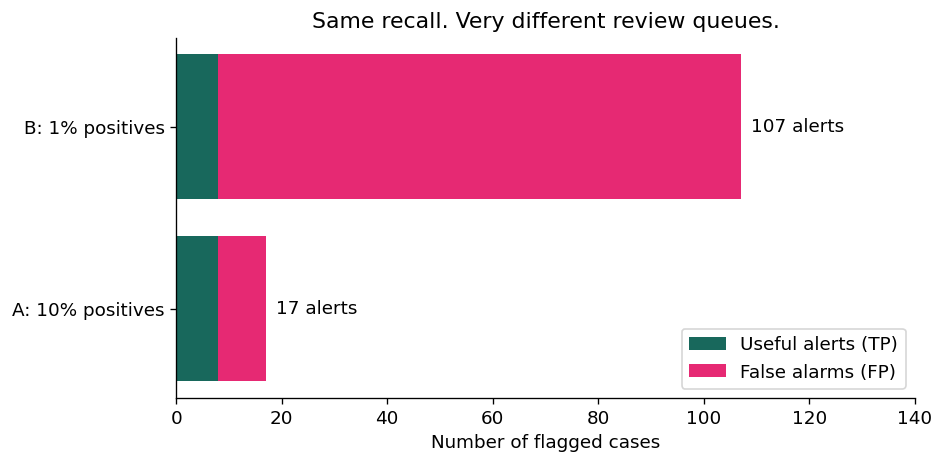

In [ ]:
def alert_summary(y, scores, threshold=.5):
    tn, fp, fn, tp = confusion_matrix(y, scores >= threshold, labels=[0, 1]).ravel()
    return dict(tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
                precision=tp/(tp+fp) if tp+fp else np.nan,
                recall=tp/(tp+fn), fpr=fp/(fp+tn))

fig, ax = plt.subplots(figsize=(8, 4))
for i, (label, (y, scores)) in enumerate(populations.items()):
    r = alert_summary(y, scores)
    print(f"{label}: TP={r['tp']}, FP={r['fp']}, recall={r['recall']:.1%}, "
          f"FPR={r['fpr']:.1%}, precision={r['precision']:.1%}")
    ax.barh(i, r['tp'], color=GREEN, label='Useful alerts (TP)' if i==0 else None)
    ax.barh(i, r['fp'], left=r['tp'], color=PINK, label='False alarms (FP)' if i==0 else None)
    ax.text(r['tp']+r['fp']+2, i, f"{r['tp']+r['fp']} alerts", va='center')
ax.set(yticks=[0,1], yticklabels=list(populations), xlabel='Number of flagged cases',
       title='Same recall. Very different review queues.', xlim=(0,140))
ax.legend(loc='lower right'); fig.tight_layout(); plt.show()

**What to notice:** Both systems catch eight positives, but B produces 99 false alarms rather than nine. Its precision is 8/107 ≈ 7.5%. The denominator matters!

## Step 4 · Compare the curves
ROC plots recall against FPR. PR plots precision against recall. Each point corresponds to an available decision rule.

We use only two score values, so there are very few operating points. Lines between them are visual connections, not additional score thresholds. The PR endpoint at recall 0 and precision 1 is a plotting convention; an empty alert queue has undefined precision.

**Predict:** Which plot will show a difference between the populations?

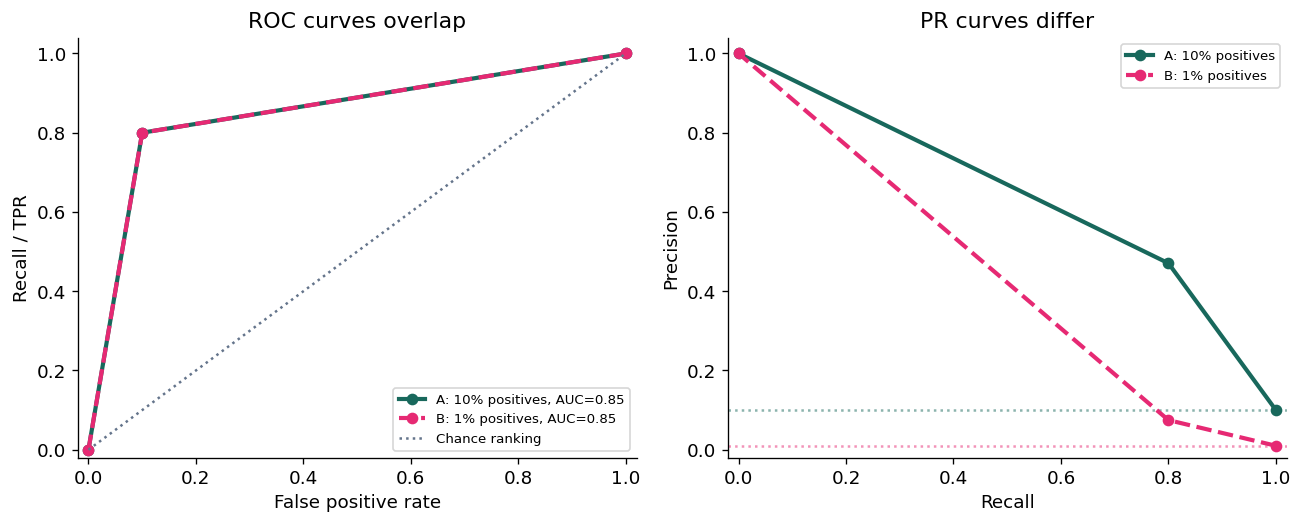

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (label, (y, scores)), color, style in zip(populations.items(), [GREEN,PINK], ['-','--']):
    fpr, tpr, _ = roc_curve(y, scores)
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[0].plot(fpr, tpr, marker='o', color=color, linestyle=style,
                 linewidth=2.5, label=f'{label}, AUC={roc_auc_score(y,scores):.2f}')
    axes[1].plot(recall, precision, marker='o', color=color, linestyle=style,
                 linewidth=2.5, label=label)
    axes[1].axhline(y.mean(), color=color, alpha=.5, linestyle=':')
axes[0].plot([0,1],[0,1], color=GRAY, linestyle=':', label='Chance ranking')
axes[0].set(title='ROC curves overlap', xlabel='False positive rate', ylabel='Recall / TPR')
axes[1].set(title='PR curves differ', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.set_xlim(-.02,1.02); ax.set_ylim(-.02,1.04); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

The ROC curves overlap because the class-conditional scores are unchanged. The horizontal dotted PR lines mark each population’s positive prevalence: a no-skill precision reference, not a universal target.

ROC AUC is still useful—it summarizes ranking across positive-negative pairs, with half credit for ties. It does not tell us how clean the alert queue will be.

## Step 5 · AP and trapezoidal PR AUC are different summaries
**Average precision (AP)** weights precision by increases in recall. **Trapezoidal PR AUC** connects neighboring points with straight lines and integrates those trapezoids.

Our two-score example makes their difference especially visible. Report the method; don’t pick whichever number looks nicer!

Population             ROC AUC        AP   Trap. PR AUC
A: 10% positives         0.850     0.396          0.645
B: 1% positives          0.850     0.062          0.438


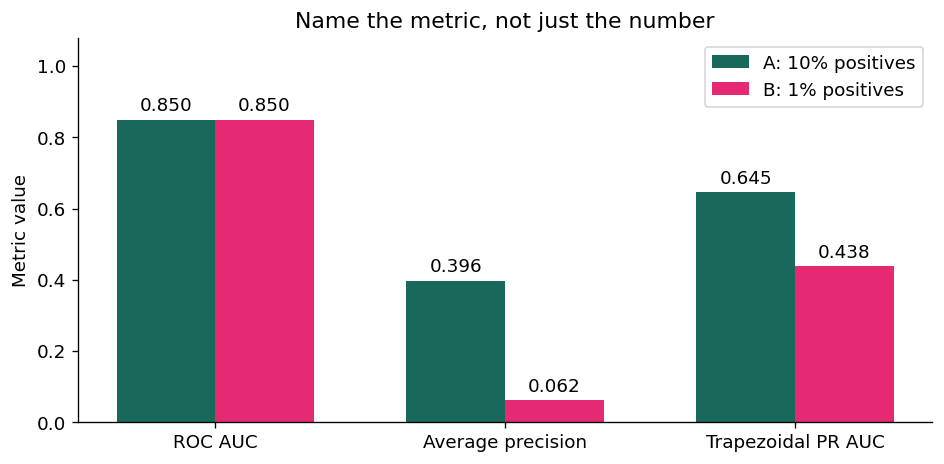

In [ ]:
metrics = {}
print(f"{'Population':<20} {'ROC AUC':>9} {'AP':>9} {'Trap. PR AUC':>14}")
for label, (y, scores) in populations.items():
    p, r, _ = precision_recall_curve(y, scores)
    ap_manual = -np.sum(np.diff(r) * p[:-1])  # sklearn returns decreasing recall
    ap = average_precision_score(y, scores)
    assert np.isclose(ap_manual, ap)
    metrics[label] = [roc_auc_score(y,scores), ap, auc(r,p)]
    print(f'{label:<20} {metrics[label][0]:9.3f} {ap:9.3f} {metrics[label][2]:14.3f}')

fig, ax = plt.subplots(figsize=(8,4))
x = np.arange(3)
for i, (label, values) in enumerate(metrics.items()):
    bars = ax.bar(x + (i-.5)*.34, values, .34, label=label, color=[GREEN,PINK][i])
    ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(xticks=x, xticklabels=['ROC AUC','Average precision','Trapezoidal PR AUC'],
       ylim=(0,1.08), ylabel='Metric value', title='Name the metric, not just the number')
ax.legend(); fig.tight_layout(); plt.show()

**Checkpoint:** A has ROC AUC 0.850, AP 0.396, and trapezoidal PR AUC 0.645. B has ROC AUC 0.850, AP 0.062, and trapezoidal PR AUC 0.438.

These are different summaries of the same scores, not three estimates of accuracy. In this example, the straight-line PR calculation is much larger than AP.

## Step 6 · Your turn: change the population 🔎
Change `N_NEGATIVE` to 190, 990, or 9990. Keep it a positive multiple of ten. You are changing prevalence while preserving within-class score behavior.

**Predict first:** As negatives increase, what happens to ROC AUC, recall, and precision at threshold 0.5?

In [ ]:
N_NEGATIVE = 190  # Try 90, 190, 990, 9990
experiment_y, experiment_scores = make_population(N_NEGATIVE)
r = alert_summary(experiment_y, experiment_scores)
print(f'Positive prevalence: {experiment_y.mean():.2%}')
print(f'ROC AUC: {roc_auc_score(experiment_y, experiment_scores):.3f}')
print(f'Average precision: {average_precision_score(experiment_y, experiment_scores):.3f}')
print(f"Recall: {r['recall']:.1%}; precision: {r['precision']:.1%}; false alarms: {r['fp']}")

### Bonus mission: turn the cutoff dial
Try 0.1, 0.5, and 0.95. With only two score levels, many cutoffs produce exactly the same decisions. `NaN` below means precision is undefined because there are no alerts.

**Question:** Does changing a threshold change ROC AUC when the underlying scores stay fixed?

In [ ]:
TRY_THRESHOLD = .5
if not 0 <= TRY_THRESHOLD <= 1:
    raise ValueError('Choose a threshold between 0 and 1.')
r = alert_summary(experiment_y, experiment_scores, TRY_THRESHOLD)
print(f"Alerts: {r['tp']+r['fp']}; TP: {r['tp']}; FP: {r['fp']}")
print(f"Precision: {r['precision']:.1%}; recall: {r['recall']:.1%}; FPR: {r['fpr']:.1%}")
print(f'ROC AUC of the unchanged scores: {roc_auc_score(experiment_y,experiment_scores):.3f}')

### Why this happens: the prevalence equation
At a fixed operating point, with positive prevalence π:

**precision = (TPR × π) / [TPR × π + FPR × (1 − π)]**

This assumes the same TPR and FPR apply to the population being considered. In real deployment, score distributions may shift as well as prevalence.

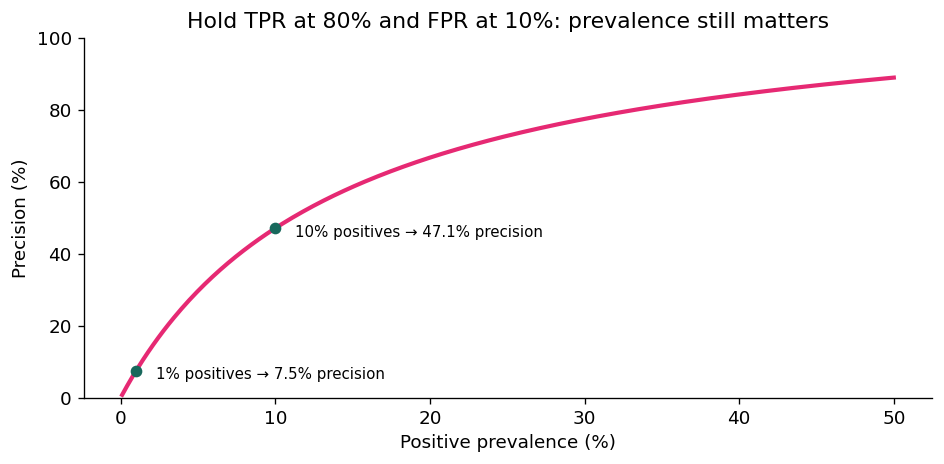

In [ ]:
prevalences = np.linspace(.001, .5, 300)
expected_precision = (.8*prevalences)/(.8*prevalences + .1*(1-prevalences))
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(prevalences*100, expected_precision*100, color=PINK, linewidth=2.5)
for prevalence in [.01,.10]:
    precision = (.8*prevalence)/(.8*prevalence+.1*(1-prevalence))
    ax.scatter(prevalence*100, precision*100, color=GREEN, zorder=3)
    ax.annotate(f'{prevalence:.0%} positives → {precision:.1%} precision',
                (prevalence*100,precision*100), xytext=(12,-5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Positive prevalence (%)', ylabel='Precision (%)', ylim=(0,100),
       title='Hold TPR at 80% and FPR at 10%: prevalence still matters')
fig.tight_layout(); plt.show()

## Your challenge · Find the largest population your alert queue can handle
Eight of ten positives score 0.9, and one in ten negatives also scores 0.9. Choose **both** the number of negatives (10 to 200, in tens) and a cutoff (0.1, 0.5, or 0.95). Find the largest population that catches at least eight positives and fits **20 reviews**. Before each trial, estimate the number of false alarms.

**Before trying it**, double-click this cell and finish the sentence: “I expect ___ because ___.”

In [ ]:
def check_queue(negatives, cutoff, predicted_false_alarms):
    if None in (negatives, cutoff, predicted_false_alarms):
        print("Choose a population and cutoff, then predict the false-alarm count.")
        return False
    if negatives not in range(10,201,10) or cutoff not in (.1,.5,.95) or not isinstance(predicted_false_alarms,int) or predicted_false_alarms < 0:
        print("Use the listed choices and a nonnegative whole-number estimate.")
        return False
    labels, scores = make_population(int(negatives))
    result = alert_summary(labels,scores,cutoff)
    alerts = result['tp'] + result['fp']
    print(f"Expected {predicted_false_alarms} false alarms; observed {result['fp']}. {result['tp']} positives caught; {alerts} reviews.")
    if result['tp'] < 8:
        print("Too few positives caught. Reconsider the cutoff.")
    elif alerts > 20:
        print("Too many reviews. Which cases can you remove while keeping the positives?")
    elif negatives < 120:
        print("Feasible. Could the team handle a larger population?")
    else:
        print("Targets met. Explain what happens if you add ten more negatives.")
        return True
    return False

**Your attempt.** Replace each `None` below with your choice. Rerun this cell after each change.

In [ ]:
negatives = None  # 10, 20, …, 200
cutoff = None  # 0.1, 0.5, or 0.95
predicted_false_alarms = None
mission_passed = check_queue(negatives, cutoff, predicted_false_alarms)

**Decision note.** Edit this cell after your experiment. “I chose ___ because I observed ___. One alternative I ruled out was ___ because ___.”

## Step 7 · Explain the result like a practitioner
Finish this sentence before reading the answers:

> “The classifier’s ROC AUC is ___, but at our selected cutoff we get ___ useful alerts and ___ false alarms. We should report ___ alongside the ranking score.”

### Take this into your next real project
- Compare candidate models on the same appropriate evaluation population. AP changes across populations can reflect prevalence.
- For rare positives, include a PR curve, explicitly named AP or PR area, and precision/recall at the intended cutoff. ROC AUC remains a useful complementary ranking metric.
- Keep evaluation representative; an artificially balanced test set does not directly estimate rare-positive deployment precision.
- Select thresholds using validation data, then evaluate on untouched test data. Use time-aware or group-aware splits where needed. This notebook constructs scores; it does not fit or select a model.
- Ranking does not prove probability calibration. There is no universal “good AP” cutoff.

**You’ve completed the lab, friends!** Next, use the [classification threshold notebook](https://colab.research.google.com/github/howtolearnmachinelearning-oss/ml-tutorials/blob/main/classification-threshold-tuning.ipynb) to connect a cutoff to error costs.

[Read the ROC AUC vs PR AUC article](https://howtolearnmachinelearning.com/articles/roc-auc-vs-pr-auc/) · [Explore the model-evaluation guide](https://howtolearnmachinelearning.com/articles/evaluating-machine-learning-models/)

### Want a learning plan?
[Get the free 90-Day Machine Learning Roadmap](https://how-to-learn-machine-learning.kit.com/7a25f667cb).

### Sources and reproducibility
- [scikit-learn: average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [scikit-learn: precision-recall guide](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)
- [Google: ROC and AUC](https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc)

The synthetic examples are deterministic. Saved outputs use the library version printed in Step 1. The two-score design intentionally emphasizes ties and the difference between integration conventions.

## Worked answers
Choose 120 negatives and cutoff 0.5. Eight true alerts leave 12 review slots for false alarms. At a 10% false-positive rate, 120 negatives fill them. Another ten negatives add one review. A cutoff of 0.95 catches nobody. At 0.1 everyone is flagged, so that cutoff can handle only ten negatives within the budget.

1. **More negatives:** ROC AUC stays 0.85 and recall stays 80% at threshold 0.5; precision falls and false-alarm counts increase. AP also falls in this constructed family.
2. **Threshold 0.1:** every case is flagged because we use `>=`; recall is 100% and precision equals prevalence.
3. **Threshold 0.95:** nothing is flagged; recall is 0% and precision is undefined.
4. **Move the cutoff:** a single decision rule changes, but ROC AUC computed from the unchanged scores stays the same. Don’t replace scores with hard predictions when calculating a ranking metric.
5. **For population B at 0.5:** 0.85 ROC AUC, eight useful alerts, 99 false alarms. Report prevalence, precision, recall, and the counts—not just AUC.

In [ ]:
for negatives in [110, 120, 130]:
    labels, scores = make_population(negatives)
    result = alert_summary(labels, scores, .5)
    print(negatives, "negatives:", result['tp'], "true alerts +", result['fp'], "false alerts")